# Part 3: Numerical Data Profiling and Outlier Detection

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(
    "../../data/Student_Depression_Dataset.xlsx"
)

In [4]:
numerical_columns = [
    "Age",
    "Current_semester",
    "CGPA",
    "Cost_without_study"
]

display(df[numerical_columns].describe())

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


### Outlier Detection Using IQR

The Interquartile Range (IQR) method is used to identify potential outliers in numerical attributes.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5(IQR)

Upper Bound = Q3 + 1.5(IQR)

Values below the lower bound or above the upper bound are identified as potential outliers.

In [6]:
outlier_results = []

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Attribute": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Number of Outliers": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Attribute,Lower Bound,Upper Bound,Number of Outliers
0,Age,16.500,28.500,0
1,Current_semester,-3.000,13.000,0
2,CGPA,2.325,4.525,12
3,Cost_without_study,-7908.500,29447.500,36


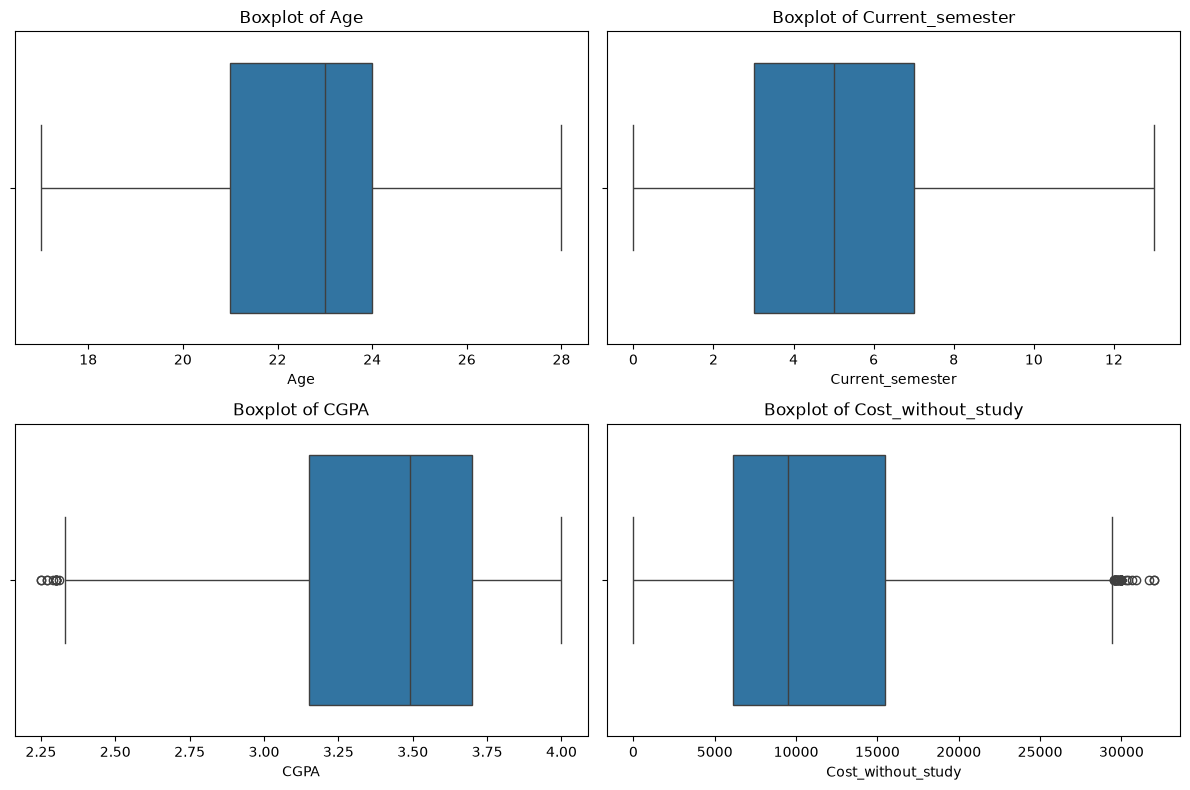

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), numerical_columns):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

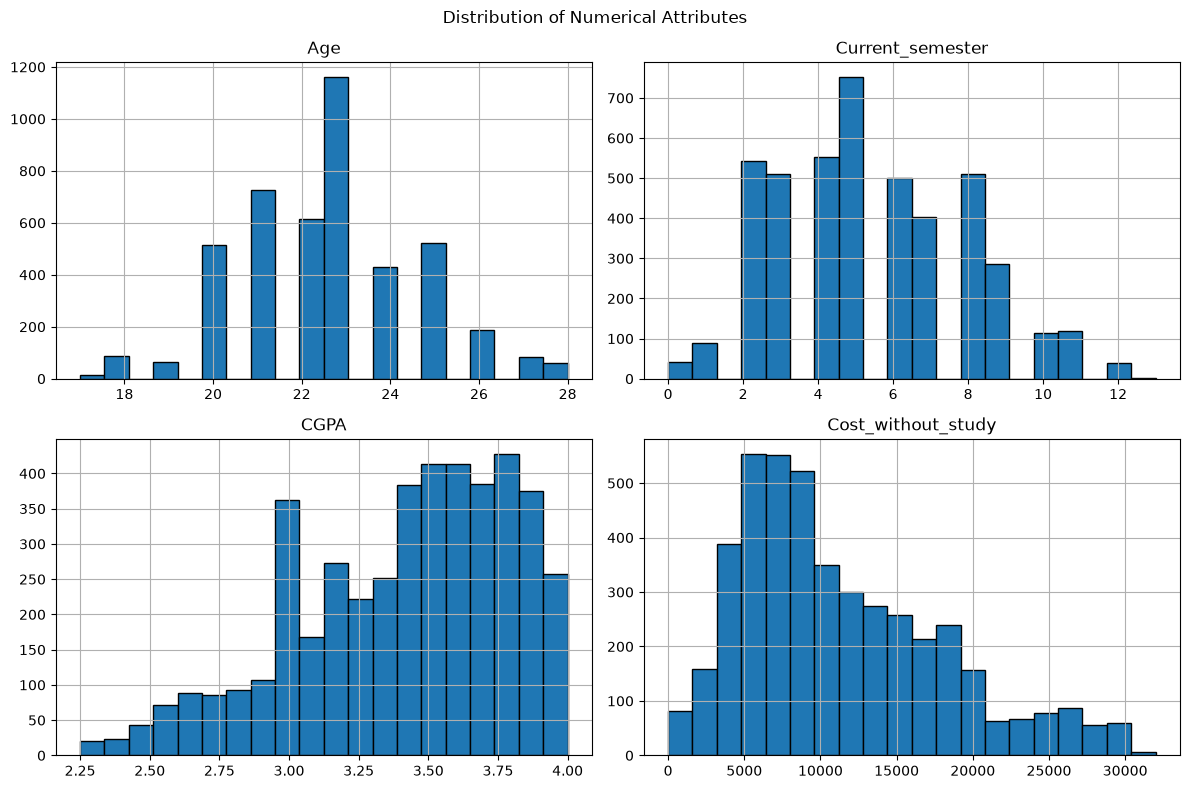

In [8]:
df[numerical_columns].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Attributes")
plt.tight_layout()
plt.show()

### Outlier Handling

The IQR method identified 12 potential outliers in CGPA and 36 potential outliers in Cost_without_study.

No outliers were identified in Age or Current_semester.

The potential outliers were retained because statistical outliers are not necessarily incorrect values. Lower CGPA values and higher financial costs may represent genuine student conditions.

Therefore, the observations were flagged for further investigation instead of automatically being removed.